<a href="https://colab.research.google.com/github/apsarak26/capstone_project_CS5998/blob/main/aeolus_feature_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive
drive.mount("/content/drive")

import pandas as pd
import zipfile

zip_path = "/content/drive/MyDrive/aeolus_v1.zip"

tables_to_explore = [
    "standard_unique_all_case.tsv",
    "standard_case_indication.tsv",
    "concept.tsv",
    "standard_case_outcome_category.tsv",
    "vocabulary.tsv"
]

table_samples = {}

with zipfile.ZipFile(zip_path, "r") as archive:

    for table_name in tables_to_explore:
        print("\n" + "=" * 70)
        print("TABLE:", table_name)
        print("=" * 70)

        with archive.open(table_name) as file:
            sample = pd.read_csv(
                file,
                sep="\t",
                header=None,
                dtype=str,
                nrows=5,
                na_values=["\\N"]
            )

        table_samples[table_name] = sample

        print("Number of columns:", sample.shape[1])
        display(sample)


Mounted at /content/drive

TABLE: standard_unique_all_case.tsv
Number of columns: 3


,0,1,2
0,9568691,95686911,NaN
1,9072290,90722901,NaN
2,10685148,106851481,NaN
3,9598597,95985971,NaN
4,10058768,100587681,NaN



TABLE: standard_case_indication.tsv
Number of columns: 6


,0,1,2,3,4,5
0,100033011,NaN,1,Product used for unknown indication,42890454,NaN
1,100033061,NaN,1,Product used for unknown indication,42890454,NaN
2,100033001,NaN,1,Osteoporosis,36416551,80502
3,NaN,6049067,1011029603,INSOMNIA,36718555,436962
4,NaN,6320997,1012098708,ASTHMA,36009700,317009



TABLE: concept.tsv
Number of columns: 10


,0,1,2,3,4,5,6,7,8,9
0,0,No matching concept,Metadata,NaN,Undefined,NaN,No matching concept,1970-01-01,2099-12-31,NaN
1,1,Domain,Metadata,Domain,Domain,NaN,OMOP generated,1970-01-01,2099-12-31,NaN
2,2,Gender,Metadata,Domain,Domain,NaN,OMOP generated,1970-01-01,2099-12-31,NaN
3,3,Race,Metadata,Domain,Domain,NaN,OMOP generated,1970-01-01,2099-12-31,NaN
4,4,Ethnicity,Metadata,Domain,Domain,NaN,OMOP generated,1970-01-01,2099-12-31,NaN



TABLE: standard_case_outcome_category.tsv
Number of columns: 4


,0,1,2,3
0,101992751,NaN,NaN,NaN
1,NaN,5508037,OT,4001594
2,NaN,5940395,OT,4001594
3,101935161,NaN,NaN,NaN
4,89828952,NaN,OT,4001594



TABLE: vocabulary.tsv
Number of columns: 5


,0,1,2,3,4
0,ABMS,Provider Specialty (American Board of Medical ...,http://www.abms.org/member-boards/specialty-su...,NaN,45756746
1,APC,Ambulatory Payment Classification (CMS),http://www.cms.gov/Medicare/Medicare-Fee-for-S...,2011-28-09,44819132
2,ATC,WHO Anatomic Therapeutic Chemical Classification,FDB UK distribution package,RxNorm Full 20150706,44819117
3,CCS,Clinical Classifications Software for ICD-9-CM...,http://www.hcup-us.ahrq.gov/toolssoftware/ccs/...,Not implemented yet,44819142
4,CIEL,Columbia International eHealth Laboratory (Col...,https://wiki.openmrs.org/display/docs/Getting+...,Openmrs 1.11.0 20150227,45905710


In [2]:

schema_summary = []

for table_name, df in table_samples.items():
    schema_summary.append({
        "table": table_name,
        "column_count": df.shape[1],
        "sample_rows": len(df)
    })

schema_df = pd.DataFrame(schema_summary)

display(schema_df)


,table,column_count,sample_rows
0,standard_unique_all_case.tsv,3,5
1,standard_case_indication.tsv,6,5
2,concept.tsv,10,5
3,standard_case_outcome_category.tsv,4,5
4,vocabulary.tsv,5,5


In [3]:

import zipfile

zip_path = "/content/drive/MyDrive/aeolus_v1.zip"

with zipfile.ZipFile(zip_path, "r") as archive:
    readme = archive.read("README.txt").decode(
        "utf-8", errors="replace"
    )

print(readme)


Filenames and description:
standard_case_drug.tsv  - Aggregated and mapped information found in the DRUGyyQq files from LAERS and FAERS. 
standard_case_outcome.tsv - Aggregated and mapped all REACyyQq files from LAERS and FAERS.
standard_case_outcome_category.tsv -  Combined SNOMED-CT outcome concept identifier with the OUTyyQq files from LAERS and FAERS.
standard_case_indication.tsv - Mapped indication preferred terms from the INDIyyQq files into OHDSI standard vocabulary concept identifiers and SNOMEDCT concept identifiers.
standard_drug_outcome_contingency_table.tsv - Contains all calculated 2x2 contingency tables for all drug-outcome combinations found in the data.
standard_drug_outcome_count.tsv - Features the total counts for all drug-outcomes are.
standard_drug_outcome_drilldown.tsv  - Contains the mapped drug/outcome pairs found in all cases (LAERS/FAERS).
standard_drug_outcome_statistics.tsv - Features for all drug-outcome pairs the PPR and ROR with their 95% confidence interv

In [4]:

import pandas as pd

indication_columns = [
    "col_0",
    "col_1",
    "col_2",
    "col_3",
    "col_4",
    "col_5"
]

indication_counts = {}
total_rows = 0
missing_counts = pd.Series(
    0, index=indication_columns, dtype="int64"
)

unique_indication_concepts = set()

with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("standard_case_indication.tsv") as file:

        for chunk in pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=indication_columns,
            dtype=str,
            na_values=["\\N"],
            chunksize=100000
        ):
            total_rows += len(chunk)
            missing_counts += chunk.isna().sum()

            # Column 3 contains indication descriptions
            counts = chunk["col_3"].value_counts()

            for term, count in counts.items():
                indication_counts[term] = (
                    indication_counts.get(term, 0) + count
                )

            unique_indication_concepts.update(
                chunk["col_4"].dropna()
            )

print("Total indication records:", total_rows)

print("\nMissing values:")
print(missing_counts)

print(
    "\nUnique indication concepts:",
    len(unique_indication_concepts)
)

top_indications = (
    pd.Series(indication_counts)
    .sort_values(ascending=False)
    .head(20)
)

display(top_indications)


Total indication records: 8637264

Missing values:
col_0    4835241
col_1    3802023
col_2          0
col_3          0
col_4          0
col_5    3072969
dtype: int64

Unique indication concepts: 14063


,0
Product used for unknown indication,820604
DRUG USE FOR UNKNOWN INDICATION,426995
PRODUCT USED FOR UNKNOWN INDICATION,388523
RHEUMATOID ARTHRITIS,191759
Multiple sclerosis,190472
HYPERTENSION,166013
Rheumatoid arthritis,149736
MULTIPLE SCLEROSIS,149726
DEPRESSION,105312
Hypertension,95643


In [5]:

import pandas as pd
import zipfile

zip_path = "/content/drive/MyDrive/aeolus_v1.zip"

case_columns = [
    "caseid",
    "primaryid",
    "isr"
]

with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("standard_unique_all_case.tsv") as file:
        case_df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=case_columns,
            dtype=str,
            na_values=["\\N"]
        )

print("Total rows:", len(case_df))
display(case_df.head())


Total rows: 4929388


,caseid,primaryid,isr
0,9568691,95686911,NaN
1,9072290,90722901,NaN
2,10685148,106851481,NaN
3,9598597,95985971,NaN
4,10058768,100587681,NaN


In [6]:

print("Missing values:")
print(case_df.isna().sum())

print("\nUnique identifiers:")
for column in case_columns:
    print(
        column,
        case_df[column].nunique(dropna=True)
    )

print("\nDuplicate rows:")
print(case_df.duplicated().sum())


Missing values:
caseid             1
primaryid    3016136
isr          1913252
dtype: int64

Unique identifiers:
caseid 4929387
primaryid 1913252
isr 3015161

Duplicate rows:
0


In [8]:
# Define the function to create a unified report ID
def create_report_id(df):
    # primaryid or isr uniquely identifies a specific report version/submission
    df['report_id'] = df['primaryid'].combine_first(df['isr'])
    return df

# Use the same report ID convention as earlier notebooks
case_df = create_report_id(case_df)

reports_per_case = (
    case_df.dropna(subset=["caseid", "report_id"])
    .groupby("caseid")["report_id"]
    .nunique()
)

print("Reports per case:")
print(reports_per_case.describe())

print(
    "\nCases with multiple report IDs:",
    (reports_per_case > 1).sum()
)

print(
    "Maximum reports per case:",
    reports_per_case.max()
)

Reports per case:
count    4929387.0
mean           1.0
std            0.0
min            1.0
25%            1.0
50%            1.0
75%            1.0
max            1.0
Name: report_id, dtype: float64

Cases with multiple report IDs: 0
Maximum reports per case: 1


In [9]:

# Investigate missing case identifiers
print("Rows with missing caseid:")
display(case_df[case_df["caseid"].isna()])

# Check whether one report ID maps to multiple case IDs
case_ids_per_report = (
    case_df.dropna(subset=["report_id", "caseid"])
    .groupby("report_id")["caseid"]
    .nunique()
)

print(
    "\nReports linked to multiple case IDs:",
    (case_ids_per_report > 1).sum()
)

print(
    "Maximum case IDs per report:",
    case_ids_per_report.max()
)

# Inspect repeated ISR values
repeated_isr = (
    case_df[case_df["isr"].notna()]
    .loc[lambda df: df["isr"].duplicated(keep=False)]
    .sort_values("isr")
)

print("\nRows with repeated ISR identifiers:", len(repeated_isr))
display(repeated_isr.head(10))


Rows with missing caseid:


,caseid,primaryid,isr,report_id
3269135,NaN,NaN,4322505,4322505



Reports linked to multiple case IDs: 975
Maximum case IDs per report: 2

Rows with repeated ISR identifiers: 1950


,caseid,primaryid,isr,report_id
3693978,5709724,NaN,4264435,4264435
242436,4055014,NaN,4264435,4264435
1083180,4057829,NaN,4267515,4267515
4714043,5709731,NaN,4267515,4267515
4088367,5709730,NaN,4267527,4267527
2450668,4057842,NaN,4267527,4267527
3664102,5709729,NaN,4267586,4267586
2926909,4057890,NaN,4267586,4267586
3761825,5709742,NaN,4270017,4270017
4914818,4062263,NaN,4270017,4270017


In [10]:
indication_columns = [
    "primaryid",
    "isr",
    "indi_drug_seq",
    "indi_pt",
    "indication_concept_id",
    "snomed_indication_concept_id"
]

In [11]:

# Recreate report IDs using our established convention
case_df = create_report_id(case_df)

# Count distinct case IDs per report
case_counts = (
    case_df.dropna(subset=["report_id", "caseid"])
    .groupby("report_id")["caseid"]
    .nunique()
)

ambiguous_report_ids = set(
    case_counts[case_counts > 1].index
)

# Preserve ambiguous mappings for investigation
ambiguous_cases_df = case_df[
    case_df["report_id"].isin(ambiguous_report_ids)
].copy()

# Keep only unambiguous, non-null mappings
clean_case_mapping = (
    case_df.dropna(subset=["report_id", "caseid"])
    .loc[
        lambda df:
        ~df["report_id"].isin(ambiguous_report_ids)
    ]
    [["report_id", "caseid"]]
    .drop_duplicates()
)

print("Clean mappings:", len(clean_case_mapping))
print("Ambiguous report IDs:", len(ambiguous_report_ids))
print("Ambiguous mapping rows:", len(ambiguous_cases_df))

print(
    "Duplicate report IDs in clean mapping:",
    clean_case_mapping["report_id"].duplicated().sum()
)


Clean mappings: 4927437
Ambiguous report IDs: 975
Ambiguous mapping rows: 1950
Duplicate report IDs in clean mapping: 0


In [12]:
import os

output_dir = "/content/drive/MyDrive/aeolus_processed"
os.makedirs(output_dir, exist_ok=True)

clean_case_mapping.to_csv(
    f"{output_dir}/clean_case_mapping.csv",
    index=False
)

ambiguous_cases_df.to_csv(
    f"{output_dir}/ambiguous_case_mapping.csv",
    index=False
)

print("Case mapping files saved.")


Case mapping files saved.


In [13]:
import pandas as pd
import zipfile
from collections import Counter

zip_path = "/content/drive/MyDrive/aeolus_v1.zip"

indication_columns = [
    "primaryid",
    "isr",
    "indi_drug_seq",
    "indi_pt",
    "indication_concept_id",
    "snomed_indication_concept_id"
]

total_rows = 0
missing_counts = Counter()
indication_counts = Counter()
unique_concept_ids = set()

with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("standard_case_indication.tsv") as file:

        for chunk in pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=indication_columns,
            dtype=str,
            na_values=["\\N"],
            chunksize=100000
        ):
            total_rows += len(chunk)

            missing_counts.update(
                chunk.isna().sum().to_dict()
            )

            indication_counts.update(
                chunk["indi_pt"].dropna().str.upper().str.strip()
            )

            unique_concept_ids.update(
                chunk["indication_concept_id"].dropna()
            )

print("Total indication records:", total_rows)

print("\nMissing values:")
for col in indication_columns:
    print(f"{col}: {missing_counts[col]:,}")

print("\nUnique indication concepts:", len(unique_concept_ids))

print("\nTop 20 reported indications:")
top_indications = pd.DataFrame(
    indication_counts.most_common(20),
    columns=["indication", "count"]
)

display(top_indications)


Total indication records: 8637264

Missing values:
primaryid: 4,835,241
isr: 3,802,023
indi_drug_seq: 0
indi_pt: 0
indication_concept_id: 0
snomed_indication_concept_id: 3,072,969

Unique indication concepts: 14063

Top 20 reported indications:


,indication,count
0,PRODUCT USED FOR UNKNOWN INDICATION,1209133
1,DRUG USE FOR UNKNOWN INDICATION,436363
2,RHEUMATOID ARTHRITIS,341502
3,MULTIPLE SCLEROSIS,340198
4,HYPERTENSION,261675
5,DIABETES MELLITUS,163224
6,DEPRESSION,150576
7,PAIN,148378
8,PERITONEAL DIALYSIS,119378
9,HEPATITIS C,115224


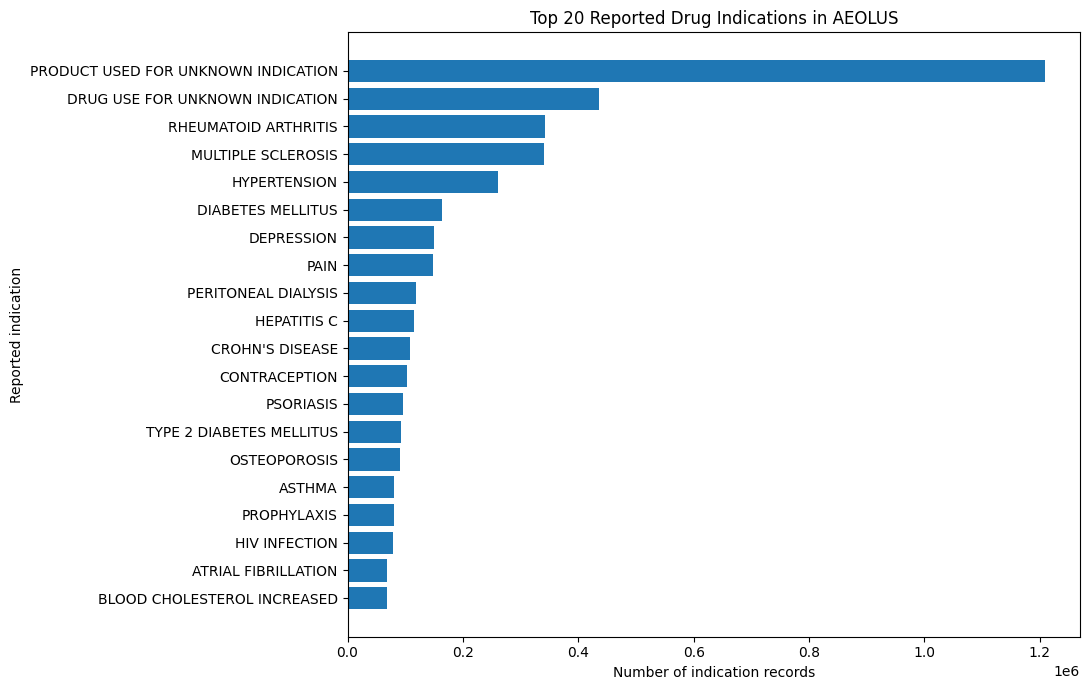

In [14]:
import matplotlib.pyplot as plt
import os

output_dir = "/content/drive/MyDrive/aeolus_processed"
os.makedirs(output_dir, exist_ok=True)

plot_df = top_indications.sort_values("count")

plt.figure(figsize=(11, 7))
plt.barh(plot_df["indication"], plot_df["count"])
plt.xlabel("Number of indication records")
plt.ylabel("Reported indication")
plt.title("Top 20 Reported Drug Indications in AEOLUS")
plt.tight_layout()

plt.savefig(
    f"{output_dir}/top_20_indications.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [15]:
import pandas as pd
import zipfile

zip_path = "/content/drive/MyDrive/aeolus_v1.zip"

drug_columns = [
    "primaryid",
    "isr",
    "drug_seq",
    "role_cod",
    "standard_concept_id"
]

ps_parts = []

with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("standard_case_drug.tsv") as file:
        for chunk in pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=drug_columns,
            dtype=str,
            na_values=["\\N"],
            chunksize=100000
        ):
            ps = chunk.loc[
                chunk["role_cod"] == "PS"
            ].copy()

            if ps.empty:
                continue

            ps = create_report_id(ps)

            ps_parts.append(
                ps[[
                    "report_id",
                    "drug_seq",
                    "standard_concept_id"
                ]]
            )

ps_drugs_df = pd.concat(
    ps_parts,
    ignore_index=True
)

print("Total PS drug records:", len(ps_drugs_df))

print("\nMissing values:")
print(ps_drugs_df.isna().sum())

print("\nSample:")
display(ps_drugs_df.head())


Total PS drug records: 4807869

Missing values:
report_id              0
drug_seq               0
standard_concept_id    0
dtype: int64

Sample:


,report_id,drug_seq,standard_concept_id
0,92198372,1,1110942
1,4634879,1005876193,1589505
2,85958942,1,904453
3,7853740,1017871507,1321636
4,5234001,1008131086,1119119


In [16]:
duplicate_keys = ps_drugs_df.duplicated(
    subset=["report_id", "drug_seq"]
).sum()

print(
    "Duplicate report + drug sequence keys:",
    duplicate_keys
)

print(
    "Unique PS report + drug sequence keys:",
    ps_drugs_df[
        ["report_id", "drug_seq"]
    ].drop_duplicates().shape[0]
)


Duplicate report + drug sequence keys: 103
Unique PS report + drug sequence keys: 4807766


In [17]:
indication_columns = [
    "primaryid",
    "isr",
    "indi_drug_seq",
    "indi_pt",
    "indication_concept_id",
    "snomed_indication_concept_id"
]

ps_keys = pd.MultiIndex.from_frame(
    ps_drugs_df[["report_id", "drug_seq"]]
    .drop_duplicates()
)

matched_keys = set()
matched_indication_rows = 0

with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("standard_case_indication.tsv") as file:

        for chunk in pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=indication_columns,
            dtype=str,
            na_values=["\\N"],
            chunksize=100000
        ):
            chunk = create_report_id(chunk)

            indication_keys = pd.MultiIndex.from_arrays([
                chunk["report_id"],
                chunk["indi_drug_seq"]
            ])

            matched = indication_keys.isin(ps_keys)

            matched_indication_rows += matched.sum()

            matched_keys.update(
                zip(
                    chunk.loc[matched, "report_id"],
                    chunk.loc[matched, "indi_drug_seq"]
                )
            )

total_ps_keys = len(ps_keys)

print("Total unique PS drug keys:", total_ps_keys)
print("Matched PS drug keys:", len(matched_keys))
print("Matched indication rows:", matched_indication_rows)

print(
    "PS drug indication coverage:",
    round(
        100 * len(matched_keys) / total_ps_keys,
        2
    ),
    "%"
)


Total unique PS drug keys: 4807766
Matched PS drug keys: 3901748
Matched indication rows: 3966647
PS drug indication coverage: 81.16 %


In [18]:
duplicate_ps = ps_drugs_df[
    ps_drugs_df.duplicated(
        subset=["report_id", "drug_seq"],
        keep=False
    )
].sort_values(["report_id", "drug_seq"])

print("Rows with duplicated PS keys:", len(duplicate_ps))

print(
    "Exact duplicate PS rows:",
    ps_drugs_df.duplicated().sum()
)

concepts_per_key = (
    ps_drugs_df.groupby(["report_id", "drug_seq"])[
        "standard_concept_id"
    ].nunique()
)

print(
    "PS keys linked to multiple drug concepts:",
    (concepts_per_key > 1).sum()
)

display(duplicate_ps.head(20))


Rows with duplicated PS keys: 206
Exact duplicate PS rows: 0
PS keys linked to multiple drug concepts: 103


,report_id,drug_seq,standard_concept_id
1203596,4434417,1005148142,785788
3454534,4434417,1005148142,40042286
3391257,4446915,1005194212,1133201
3928808,4446915,1005194212,19026972
1973047,4531234,1005505421,1107830
2511247,4531234,1005505421,40146904
440487,4639935,1005894909,40039807
2267833,4639935,1005894909,1549786
2396561,4642347,1005903529,40039807
3184700,4642347,1005903529,1549786


In [19]:
from collections import Counter

unknown_terms = {
    "PRODUCT USED FOR UNKNOWN INDICATION",
    "DRUG USE FOR UNKNOWN INDICATION"
}

ps_keys = pd.MultiIndex.from_frame(
    ps_drugs_df[["report_id", "drug_seq"]]
    .drop_duplicates()
)

known_indication_keys = set()
unknown_indication_keys = set()
indications_per_key = Counter()

with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("standard_case_indication.tsv") as file:

        for chunk in pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=indication_columns,
            dtype=str,
            na_values=["\\N"],
            chunksize=100000
        ):
            chunk = create_report_id(chunk)

            keys = pd.MultiIndex.from_arrays([
                chunk["report_id"],
                chunk["indi_drug_seq"]
            ])

            matched = chunk.loc[keys.isin(ps_keys)].copy()

            if matched.empty:
                continue

            matched["indi_pt_normalized"] = (
                matched["indi_pt"]
                .fillna("")
                .str.upper()
                .str.strip()
            )

            for (report_id, drug_seq), group in matched.groupby(
                ["report_id", "indi_drug_seq"]
            ):
                key = (report_id, drug_seq)

                indications_per_key[key] += len(group)

                if group["indi_pt_normalized"].isin(
                    unknown_terms
                ).any():
                    unknown_indication_keys.add(key)

                if (
                    ~group["indi_pt_normalized"].isin(
                        unknown_terms
                    )
                ).any():
                    known_indication_keys.add(key)

print("PS keys with any indication:", len(indications_per_key))
print("PS keys with known indications:", len(known_indication_keys))
print("PS keys with unknown indication terms:", len(unknown_indication_keys))

print(
    "Known indication coverage:",
    round(
        len(known_indication_keys) / len(ps_keys) * 100,
        2
    ),
    "%"
)

print(
    "PS keys with multiple indication rows:",
    sum(v > 1 for v in indications_per_key.values())
)

print(
    "Maximum indication rows per PS key:",
    max(indications_per_key.values())
)


KeyboardInterrupt: 

In [20]:
import pandas as pd
import zipfile

unknown_terms = {
    "PRODUCT USED FOR UNKNOWN INDICATION",
    "DRUG USE FOR UNKNOWN INDICATION"
}

# Existing PS keys
ps_keys = pd.MultiIndex.from_frame(
    ps_drugs_df[["report_id", "drug_seq"]]
    .drop_duplicates()
)

matched_parts = []

with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("standard_case_indication.tsv") as file:

        for chunk in pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=indication_columns,
            dtype=str,
            na_values=["\\N"],
            chunksize=200000
        ):
            chunk = create_report_id(chunk)

            keys = pd.MultiIndex.from_arrays([
                chunk["report_id"],
                chunk["indi_drug_seq"]
            ])

            matched = chunk.loc[
                keys.isin(ps_keys),
                ["report_id", "indi_drug_seq", "indi_pt"]
            ].copy()

            if matched.empty:
                continue

            matched["is_unknown"] = (
                matched["indi_pt"]
                .fillna("")
                .str.upper()
                .str.strip()
                .isin(unknown_terms)
            )

            matched_parts.append(matched)

matched_indications_df = pd.concat(
    matched_parts,
    ignore_index=True
)

print("Matched indication rows:", len(matched_indications_df))


Matched indication rows: 3966647


In [21]:
grouped = matched_indications_df.groupby(
    ["report_id", "indi_drug_seq"],
    sort=False
)

summary = grouped["is_unknown"].agg(
    indication_count="size",
    all_unknown="all",
    any_unknown="any"
)

total_keys = len(ps_keys)

print("PS keys with any indication:", len(summary))

print(
    "PS keys with known indications:",
    (~summary["all_unknown"]).sum()
)

print(
    "PS keys with unknown indication terms:",
    summary["any_unknown"].sum()
)

print(
    "Known indication coverage:",
    round(
        (~summary["all_unknown"]).sum()
        / total_keys * 100,
        2
    ),
    "%"
)

print(
    "PS keys with multiple indication rows:",
    (summary["indication_count"] > 1).sum()
)

print(
    "Maximum indication rows per PS key:",
    summary["indication_count"].max()
)


PS keys with any indication: 3901748
PS keys with known indications: 3453602
PS keys with unknown indication terms: 448383
Known indication coverage: 71.83 %
PS keys with multiple indication rows: 57190
Maximum indication rows per PS key: 15


In [22]:

import pandas as pd
import zipfile

concept_columns = [
    "concept_id",
    "concept_name",
    "domain_id",
    "vocabulary_id",
    "concept_class_id",
    "standard_concept",
    "concept_code",
    "valid_start_date",
    "valid_end_date",
    "invalid_reason"
]

ps_concept_ids = set(
    ps_drugs_df["standard_concept_id"].dropna().astype(str)
)

concept_parts = []

with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("concept.tsv") as file:

        for chunk in pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=concept_columns,
            dtype=str,
            na_values=["\\N"],
            chunksize=100000
        ):
            matched = chunk[
                chunk["concept_id"].isin(ps_concept_ids)
            ]

            if not matched.empty:
                concept_parts.append(matched.copy())

ps_concepts_df = pd.concat(
    concept_parts,
    ignore_index=True
)

print("Unique PS concept IDs:", len(ps_concept_ids))
print("Concepts found:", ps_concepts_df["concept_id"].nunique())

print(
    "Unmatched concept IDs:",
    len(
        ps_concept_ids -
        set(ps_concepts_df["concept_id"])
    )
)

display(
    ps_concepts_df[
        [
            "concept_id",
            "concept_name",
            "domain_id",
            "vocabulary_id",
            "concept_class_id",
            "standard_concept",
            "invalid_reason"
        ]
    ].head(20)
)


Unique PS concept IDs: 2368
Concepts found: 2332
Unmatched concept IDs: 36


,concept_id,concept_name,domain_id,vocabulary_id,concept_class_id,standard_concept,invalid_reason
0,501343,hepatitis B immune globulin,Drug,RxNorm,Ingredient,S,NaN
1,523367,"poliovirus vaccine inactivated, type 3 (Saukett)",Drug,RxNorm,Ingredient,S,NaN
2,528301,Neisseria meningitidis serogroup Y capsular po...,Drug,RxNorm,Ingredient,S,NaN
3,528323,Hepatitis B Surface Antigen Vaccine,Drug,RxNorm,Ingredient,S,NaN
4,529116,"L1 protein, Human papillomavirus type 6 Vaccine",Drug,RxNorm,Ingredient,S,NaN
5,529118,"Haemophilus influenzae type b, capsular polysa...",Drug,RxNorm,Ingredient,S,NaN
6,529216,Human-Bovine Reassortant Rotavirus Strain P1A[...,Drug,RxNorm,Ingredient,S,NaN
7,529411,"tetanus toxoid vaccine, inactivated",Drug,RxNorm,Ingredient,S,NaN
8,529660,Hepatitis A Vaccine (Inactivated) Strain HM175,Drug,RxNorm,Ingredient,S,NaN
9,532272,"Measles Virus Vaccine Live, Enders' attenuated...",Drug,RxNorm,Ingredient,S,NaN


In [23]:
for column in [
    "domain_id",
    "vocabulary_id",
    "concept_class_id",
    "standard_concept",
    "invalid_reason"
]:
    print(f"\n{column}:")
    display(
        ps_concepts_df[column]
        .fillna("MISSING")
        .value_counts()
        .head(20)
    )



domain_id:


,count
domain_id,
Drug,2332



vocabulary_id:


,count
vocabulary_id,
RxNorm,2332



concept_class_id:


,count
concept_class_id,
Ingredient,2035
Clinical Drug Form,297



standard_concept:


,count
standard_concept,
S,2332



invalid_reason:


,count
invalid_reason,
MISSING,2332


In [24]:
import os

output_dir = "/content/drive/MyDrive/aeolus_processed"
os.makedirs(output_dir, exist_ok=True)

ps_concepts_df.to_csv(
    f"{output_dir}/ps_drug_concept_mapping.csv",
    index=False
)

print("Drug concept mapping saved.")


Drug concept mapping saved.


In [25]:
mapped_ids = set(
    ps_concepts_df["concept_id"].astype(str)
)

unmatched_ids = ps_concept_ids - mapped_ids

unmatched_drugs = ps_drugs_df[
    ps_drugs_df["standard_concept_id"].isin(
        unmatched_ids
    )
].copy()

unmatched_summary = (
    unmatched_drugs["standard_concept_id"]
    .value_counts()
    .rename_axis("concept_id")
    .reset_index(name="record_count")
)

print("Unmatched concept IDs:", len(unmatched_ids))
print("PS records affected:", len(unmatched_drugs))

print(
    "Percentage of PS records affected:",
    round(
        len(unmatched_drugs) / len(ps_drugs_df) * 100,
        4
    ),
    "%"
)

display(unmatched_summary)


Unmatched concept IDs: 36
PS records affected: 2582
Percentage of PS records affected: 0.0537 %


,concept_id,record_count
0,45775372,951
1,45775965,414
2,45776001,177
3,45774751,164
4,45776270,159
5,45776944,158
6,45775020,111
7,45774639,100
8,45775206,88
9,45775396,44


In [26]:
duplicate_ps_details = duplicate_ps.merge(
    ps_concepts_df[
        [
            "concept_id",
            "concept_name",
            "concept_class_id"
        ]
    ],
    left_on="standard_concept_id",
    right_on="concept_id",
    how="left",
    validate="many_to_one"
)

display(
    duplicate_ps_details[
        [
            "report_id",
            "drug_seq",
            "standard_concept_id",
            "concept_name",
            "concept_class_id"
        ]
    ].head(30)
)


,report_id,drug_seq,standard_concept_id,concept_name,concept_class_id
0,4434417,1005148142,785788,olanzapine,Ingredient
1,4434417,1005148142,40042286,Fluoxetine / olanzapine Oral Capsule,Clinical Drug Form
2,4446915,1005194212,1133201,Buprenorphine,Ingredient
3,4446915,1005194212,19026972,lenalidomide,Ingredient
4,4531234,1005505421,1107830,Loratadine,Ingredient
5,4531234,1005505421,40146904,Loratadine / Pseudoephedrine Oral Solution,Clinical Drug Form
6,4639935,1005894909,40039807,Ethinyl Estradiol / norgestimate Oral Tablet,Clinical Drug Form
7,4639935,1005894909,1549786,Ethinyl Estradiol,Ingredient
8,4642347,1005903529,40039807,Ethinyl Estradiol / norgestimate Oral Tablet,Clinical Drug Form
9,4642347,1005903529,1549786,Ethinyl Estradiol,Ingredient


In [27]:

import pandas as pd
import os

output_dir = "/content/drive/MyDrive/aeolus_processed"
os.makedirs(output_dir, exist_ok=True)

# Identify keys associated with multiple drug concepts
concepts_per_key = (
    ps_drugs_df
    .groupby(["report_id", "drug_seq"])[
        "standard_concept_id"
    ]
    .nunique()
)

ambiguous_keys = concepts_per_key[
    concepts_per_key > 1
].index

# Save detailed ambiguous mappings
ambiguous_drugs = (
    ps_drugs_df
    .set_index(["report_id", "drug_seq"])
    .loc[ambiguous_keys]
    .reset_index()
)

ambiguous_drugs = ambiguous_drugs.merge(
    ps_concepts_df[
        ["concept_id", "concept_name", "concept_class_id"]
    ],
    left_on="standard_concept_id",
    right_on="concept_id",
    how="left",
    validate="many_to_one"
)

ambiguous_drugs.to_csv(
    f"{output_dir}/ambiguous_ps_drug_concepts.csv",
    index=False
)

# Save unmatched concept frequency
unmatched_summary.to_csv(
    f"{output_dir}/unmatched_ps_concepts.csv",
    index=False
)

quality_summary = pd.DataFrame({
    "metric": [
        "Total PS drug records",
        "Unique PS drug keys",
        "Unique PS concepts",
        "Mapped PS concepts",
        "Unmatched PS concepts",
        "PS records with unmatched concepts",
        "PS keys with multiple concepts"
    ],
    "value": [
        len(ps_drugs_df),
        len(concepts_per_key),
        len(ps_concept_ids),
        ps_concepts_df["concept_id"].nunique(),
        len(unmatched_ids),
        len(unmatched_drugs),
        len(ambiguous_keys)
    ]
})

quality_summary.to_csv(
    f"{output_dir}/drug_concept_quality_summary.csv",
    index=False
)

display(quality_summary)
print("Quality reports saved.")


,metric,value
0,Total PS drug records,4807869
1,Unique PS drug keys,4807766
2,Unique PS concepts,2368
3,Mapped PS concepts,2332
4,Unmatched PS concepts,36
5,PS records with unmatched concepts,2582
6,PS keys with multiple concepts,103


Quality reports saved.
